# Day 4: CNN on MFCC "pictures"
Needs: data/metadata.csv, features/X_mfcc.npy, features/y.npy (made on Day 3).
Only ONE thing to edit: the BASE address in the first code cell.

In [1]:
# 1. THE ONLY ADDRESS YOU NEED (same as before)
BASE = r"C:\Users\Abdul Rehman\Documents\Projects\emotion-recognition"     # <-- change this to your folder

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

BASE = Path(BASE)
tf.keras.utils.set_random_seed(42)
EPOCHS = 60

df = pd.read_csv(BASE / "data" / "metadata.csv")
X = np.load(BASE / "features" / "X_mfcc.npy")           # (1440, 40, 130)
y = np.load(BASE / "features" / "y.npy")                # (1440,)
classes = json.load(open(BASE / "models" / "classes.json"))

tr = (df["actor"] <= 16).values
va = df["actor"].between(17, 20).values
print("X:", X.shape, "| train:", tr.sum(), "| validation:", va.sum())

X: (1440, 40, 130) | train: 960 | validation: 240


In [2]:
# 2. Normalise using TRAINING statistics only, and save them (the app needs them on Day 7)
mean = X[tr].mean(axis=(0, 2), keepdims=True)           # (1, 40, 1)
std = X[tr].std(axis=(0, 2), keepdims=True) + 1e-8
np.savez(BASE / "models" / "norm.npz", mean=mean[0], std=std[0])

Xc = ((X - mean) / std)[..., np.newaxis]                # (1440, 40, 130, 1)
print("Model input shape:", Xc.shape)

# Neutral has half as many clips as the other emotions, so give each class a fair weight
cw = compute_class_weight("balanced", classes=np.arange(8), y=y[tr])
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {classes[i]: round(w, 2) for i, w in class_weight.items()})

Model input shape: (1440, 40, 130, 1)
Class weights: {'angry': 0.94, 'calm': 0.94, 'disgust': 0.94, 'fearful': 0.94, 'happy': 0.94, 'neutral': 1.88, 'sad': 0.94, 'surprised': 0.94}


In [3]:
# 3. Build the CNN
def build_cnn(lr=1e-3, dropout=0.4, width=32):
    m = models.Sequential([
        layers.Input(shape=(40, 130, 1)),
        layers.Conv2D(width, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 2, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 4, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9), layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(8, activation="softmax"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cnn = build_cnn()
cnn.summary()
# Write down what each layer does to the shape of the data.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 130, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 130, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,344 (399.78 KB)

 Trainable params: 101,896 (398.03 KB)

 Non-trainable params: 448 (1.75 KB)

In [4]:
# 4. Train (early stopping keeps the epoch with the best VALIDATION ACCURACY; this can take a few minutes)
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=20, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=5, min_lr=1e-5),
]
hist = cnn.fit(Xc[tr], y[tr], validation_data=(Xc[va], y[va]),
               epochs=EPOCHS, batch_size=32, class_weight=class_weight,
               callbacks=callbacks, verbose=2)

Epoch 1/60
30/30 - 10s - 332ms/step - accuracy: 0.2542 - loss: 1.9309 - val_accuracy: 0.1333 - val_loss: 2.2908 - learning_rate: 0.0010
Epoch 2/60
30/30 - 5s - 183ms/step - accuracy: 0.3604 - loss: 1.7223 - val_accuracy: 0.2500 - val_loss: 1.8203 - learning_rate: 0.0010
Epoch 3/60
30/30 - 5s - 183ms/step - accuracy: 0.4229 - loss: 1.5790 - val_accuracy: 0.3958 - val_loss: 1.6003 - learning_rate: 0.0010
Epoch 4/60
30/30 - 5s - 182ms/step - accuracy: 0.4760 - loss: 1.4384 - val_accuracy: 0.3917 - val_loss: 1.5674 - learning_rate: 0.0010
Epoch 5/60
30/30 - 5s - 180ms/step - accuracy: 0.5240 - loss: 1.3395 - val_accuracy: 0.4125 - val_loss: 1.5012 - learning_rate: 0.0010
Epoch 6/60
30/30 - 5s - 183ms/step - accuracy: 0.5667 - loss: 1.2187 - val_accuracy: 0.4167 - val_loss: 1.5385 - learning_rate: 0.0010
Epoch 7/60
30/30 - 6s - 185ms/step - accuracy: 0.6125 - loss: 1.1325 - val_accuracy: 0.3667 - val_loss: 1.7854 - learning_rate: 0.0010
Epoch 8/60
30/30 - 5s - 181ms/step - accuracy: 0.6260 

Trained 35 epochs | best validation accuracy 0.533 at epoch 15


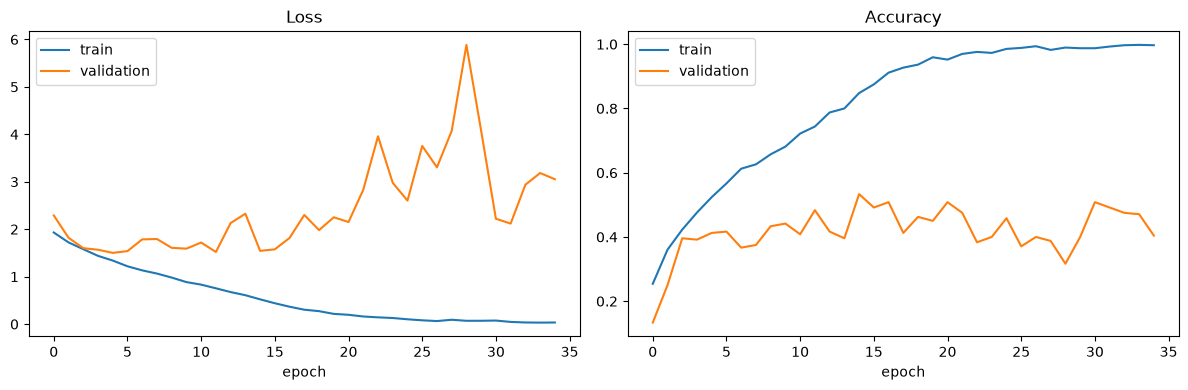

In [5]:
# 5. Learning curves (a big gap between train and validation means overfitting)
best_epoch = int(np.argmax(hist.history["val_accuracy"])) + 1
print(f"Trained {len(hist.history['loss'])} epochs | best validation accuracy "
      f"{max(hist.history['val_accuracy']):.3f} at epoch {best_epoch}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history["loss"], label="train"); axes[0].plot(hist.history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist.history["accuracy"], label="train"); axes[1].plot(hist.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

Validation accuracy: 0.533 | macro-F1: 0.484
              precision    recall  f1-score   support

       angry       0.74      0.53      0.62        32
        calm       0.60      0.78      0.68        32
     disgust       0.59      0.62      0.61        32
     fearful       0.42      0.84      0.56        32
       happy       0.00      0.00      0.00        32
     neutral       0.40      0.50      0.44        16
         sad       0.62      0.25      0.36        32
   surprised       0.53      0.72      0.61        32

    accuracy                           0.53       240
   macro avg       0.49      0.53      0.48       240
weighted avg       0.49      0.53      0.49       240



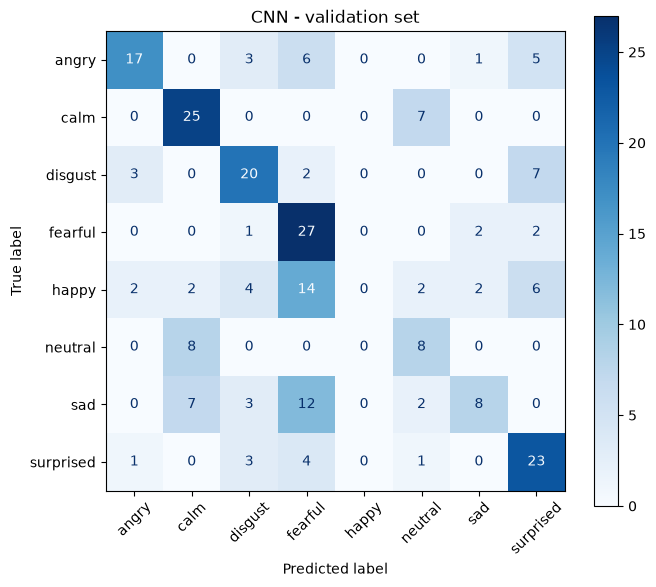

In [6]:
# 6. Evaluate on the VALIDATION set (not the test set!)
pred = cnn.predict(Xc[va], verbose=0).argmax(axis=1)
acc = accuracy_score(y[va], pred)
f1 = f1_score(y[va], pred, average="macro")
print(f"Validation accuracy: {acc:.3f} | macro-F1: {f1:.3f}")
print(classification_report(y[va], pred, target_names=classes, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y[va], pred, display_labels=classes,
                                        xticks_rotation=45, cmap="Blues", ax=ax)
plt.title("CNN - validation set")
plt.tight_layout()
plt.show()

In [7]:
# 7. Save the model and add the result to results.csv
cnn.save(BASE / "models" / "cnn.keras")

RESULTS = BASE / "results.csv"
def save_result(name, acc, f1):
    row = pd.DataFrame([{"model": name, "val_accuracy": round(float(acc), 4), "val_macro_f1": round(float(f1), 4)}])
    if RESULTS.exists():
        old = pd.read_csv(RESULTS)
        old = old[old["model"] != name]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(RESULTS, index=False)
    print(row.to_string(index=False))

save_result("CNN", acc, f1)

       model  val_accuracy  val_macro_f1
Baseline SVM        0.4708        0.4536
         CNN        0.5333        0.4837


In [8]:
true_names = pd.Series([classes[i] for i in y[va]], name="true")
pred_names = pd.Series([classes[i] for i in pred], name="predicted")
print("Predicted counts:", pred_names.value_counts().to_dict())
pd.crosstab(true_names, pred_names)

Predicted counts: {'fearful': 65, 'surprised': 43, 'calm': 42, 'disgust': 34, 'angry': 23, 'neutral': 20, 'sad': 13}


predicted,angry,calm,disgust,fearful,neutral,sad,surprised
true,,,,,,,
angry,17,0,3,6,0,1,5
calm,0,25,0,0,7,0,0
disgust,3,0,20,2,0,0,7
fearful,0,0,1,27,0,2,2
happy,2,2,4,14,2,2,6
neutral,0,8,0,0,8,0,0
sad,0,7,3,12,2,8,0
surprised,1,0,3,4,1,0,23
